In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [76]:
BASE_URL = "https://raw.githubusercontent.com/yassin-islam10/student-grade-prediction/main"

d1 = pd.read_csv(f"{BASE_URL}/student-mat.csv", sep=";")
d2 = pd.read_csv(f"{BASE_URL}/student-por.csv", sep=";")

print("Math dataset shape:", d1.shape)
print("Portuguese dataset shape:", d2.shape)

Math dataset shape: (395, 33)
Portuguese dataset shape: (649, 33)


In [111]:
d1.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [78]:
d3.shape

(382, 53)

In [79]:
d3.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian_x', 'traveltime_x', 'studytime_x',
       'failures_x', 'schoolsup_x', 'famsup_x', 'paid_x', 'activities_x',
       'nursery', 'higher_x', 'internet', 'romantic_x', 'famrel_x',
       'freetime_x', 'goout_x', 'Dalc_x', 'Walc_x', 'health_x', 'absences_x',
       'G1_x', 'G2_x', 'G3_x', 'guardian_y', 'traveltime_y', 'studytime_y',
       'failures_y', 'schoolsup_y', 'famsup_y', 'paid_y', 'activities_y',
       'higher_y', 'romantic_y', 'famrel_y', 'freetime_y', 'goout_y', 'Dalc_y',
       'Walc_y', 'health_y', 'absences_y', 'G1_y', 'G2_y', 'G3_y'],
      dtype='object')

In [80]:
print("Math duplicate keys:",
      d1.duplicated(subset=merge_cols).sum())

print("Portuguese duplicate keys:",
      d2.duplicated(subset=merge_cols).sum())

Math duplicate keys: 4
Portuguese duplicate keys: 12


In [81]:
# Count occurrences of each merge key
math_counts = (
    d1.groupby(merge_cols, dropna=False)
    .size()
    .rename("math_rows")
)

por_counts = (
    d2.groupby(merge_cols, dropna=False)
    .size()
    .rename("por_rows")
)

# Combine both counts
key_audit = pd.concat(
    [math_counts, por_counts],
    axis=1
).fillna(0).astype(int)

# Find keys that are not unique
ambiguous_keys = key_audit[
    (key_audit["math_rows"] > 1) |
    (key_audit["por_rows"] > 1)
]

print("Ambiguous keys:")
display(ambiguous_keys.reset_index())

# Check common keys
common_keys = key_audit[
    (key_audit["math_rows"] > 0) &
    (key_audit["por_rows"] > 0)
]

print("Common keys:", len(common_keys))

print(
    "Expected merge rows:",
    (common_keys["math_rows"] * common_keys["por_rows"]).sum()
)

print("Actual merge rows:", len(d3))

print(
    "One-to-one matched keys:",
    (
        (common_keys["math_rows"] == 1) &
        (common_keys["por_rows"] == 1)
    ).sum()
)

Ambiguous keys:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,nursery,internet,math_rows,por_rows
0,GP,F,17,U,GT3,T,4,4,teacher,services,course,yes,yes,1,2
1,GP,F,18,U,GT3,T,1,1,other,other,home,yes,yes,1,2
2,GP,M,16,U,GT3,T,3,3,services,other,home,yes,yes,2,2
3,GP,M,16,U,GT3,T,4,4,services,services,course,yes,yes,1,2
4,GP,M,16,U,GT3,T,4,4,teacher,teacher,course,yes,yes,2,2
5,GP,M,17,U,GT3,T,2,1,other,other,home,yes,yes,2,2
6,GP,M,18,U,GT3,T,4,4,teacher,services,home,yes,yes,2,2
7,MS,F,18,U,GT3,T,1,1,other,other,course,yes,no,1,2
8,MS,F,16,R,GT3,T,2,2,other,other,course,yes,yes,0,3
9,MS,F,16,U,GT3,T,1,2,other,services,course,yes,no,0,2


Common keys: 366
Expected merge rows: 382
Actual merge rows: 382
One-to-one matched keys: 358


In [82]:
dup_math = d1[
    d1.duplicated(subset=merge_cols, keep=False)
].sort_values(merge_cols)

dup_por = d2[
    d2.duplicated(subset=merge_cols, keep=False)
].sort_values(merge_cols)

display(dup_math)
display(dup_por)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
107,GP,M,16,U,GT3,T,3,3,services,other,...,5,3,3,1,1,5,2,16,18,18
181,GP,M,16,U,GT3,T,3,3,services,other,...,4,2,3,1,2,3,2,12,13,12
115,GP,M,16,U,GT3,T,4,4,teacher,teacher,...,5,4,4,1,2,5,2,15,15,16
148,GP,M,16,U,GT3,T,4,4,teacher,teacher,...,3,3,2,2,1,5,0,7,6,0
78,GP,M,17,U,GT3,T,2,1,other,other,...,4,5,1,1,1,3,2,8,8,10
144,GP,M,17,U,GT3,T,2,1,other,other,...,5,4,5,1,2,5,0,5,0,0
277,GP,M,18,U,GT3,T,4,4,teacher,services,...,3,2,4,1,4,3,22,9,9,9
341,GP,M,18,U,GT3,T,4,4,teacher,services,...,4,3,3,2,2,2,0,10,10,0


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
271,GP,F,17,U,GT3,T,4,4,teacher,services,...,5,3,1,1,4,5,2,11,11,12
380,GP,F,17,U,GT3,T,4,4,teacher,services,...,5,4,4,1,3,4,0,13,12,13
328,GP,F,18,U,GT3,T,1,1,other,other,...,5,4,4,1,1,4,0,12,13,13
376,GP,F,18,U,GT3,T,1,1,other,other,...,4,5,5,1,2,2,0,14,14,14
107,GP,M,16,U,GT3,T,3,3,services,other,...,5,3,3,1,1,5,4,13,14,14
195,GP,M,16,U,GT3,T,3,3,services,other,...,4,2,3,1,2,3,0,11,12,13
151,GP,M,16,U,GT3,T,4,4,services,services,...,5,3,3,1,3,5,0,15,13,13
270,GP,M,16,U,GT3,T,4,4,services,services,...,5,3,2,1,2,5,4,14,15,15
115,GP,M,16,U,GT3,T,4,4,teacher,teacher,...,5,4,4,1,2,5,6,16,14,14
161,GP,M,16,U,GT3,T,4,4,teacher,teacher,...,3,3,2,2,1,5,16,9,9,8


In [83]:
# Keep only keys existing in both datasets
shared = key_audit[
    (key_audit["math_rows"] > 0) &
    (key_audit["por_rows"] > 0)
]

# Find ambiguous shared keys
ambiguous_shared = shared[
    (shared["math_rows"] > 1) |
    (shared["por_rows"] > 1)
]

print("Distinct common keys:", len(shared))

print("One-to-one keys:",
      ((shared["math_rows"] == 1) &
       (shared["por_rows"] == 1)).sum())

print("Ambiguous shared keys:", len(ambiguous_shared))

print("Expected merge rows:",
      (shared["math_rows"] * shared["por_rows"]).sum())

display(ambiguous_shared[["math_rows", "por_rows"]])

Distinct common keys: 366
One-to-one keys: 358
Ambiguous shared keys: 8
Expected merge rows: 382


math_rows  \
school sex age address famsize Pstatus Medu Fedu Mjob     Fjob     reason nursery internet              
GP     F   17  U       GT3     T       4    4    teacher  services course yes     yes               1   
           18  U       GT3     T       1    1    other    other    home   yes     yes               1   
       M   16  U       GT3     T       3    3    services other    home   yes     yes               2   
                                       4    4    services services course yes     yes               1   
                                                 teacher  teacher  course yes     yes               2   
           17  U       GT3     T       2    1    other    other    home   yes     yes               2   
           18  U       GT3     T       4    4    teacher  services home   yes     yes               2   
MS     F   18  U       GT3     T       1    1    other    other    course yes     no                1   

                                                                                            por_rows  
school sex age address famsize Pstatus Medu Fedu Mjob     Fjob     reason nursery internet            
GP     F   17  U       GT3     T       4    4    teacher  services course yes     yes              2  
           18  U       GT3     T       1    1    other    other    home   yes     yes              2  
       M   16  U       GT3     T       3    3    services other    home   yes     yes              2  
                                       4    4    services services course yes     yes              2  
                                                 teacher  teacher  course yes     yes              2  
           17  U       GT3     T       2    1    other    other    home   yes     yes              2  
           18  U       GT3     T       4    4    teacher  services home   yes     yes              2  
MS     F   18  U       GT3     T       1    1    other    other    course yes     no               2

In [84]:
df = d1.copy()

print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicated Full Rows:")
print(df.duplicated().sum())

Dataset Shape: (395, 33)

Columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Data Types:
school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       

In [85]:
# Statistical summary of important features

important_cols = [
    "studytime",
    "absences",
    "Medu",
    "Fedu",
    "failures",
    "G1",
    "G2",
    "G3"
]

display(df[important_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
absences,395.0,5.708861,8.003096,0.0,0.0,4.0,8.0,75.0
Medu,395.0,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
failures,395.0,0.334177,0.743651,0.0,0.0,0.0,0.0,3.0
G1,395.0,10.908861,3.319195,3.0,8.0,11.0,13.0,19.0
G2,395.0,10.713924,3.761505,0.0,9.0,11.0,13.0,19.0
G3,395.0,10.415190,4.581443,0.0,8.0,11.0,14.0,20.0


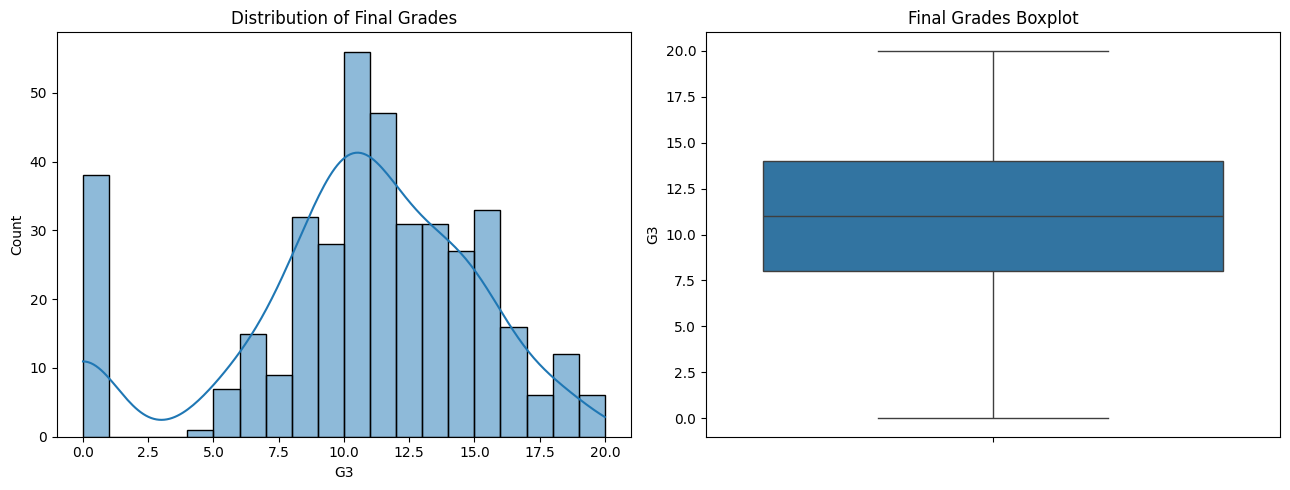

In [86]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(data=df, x="G3", bins=20, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Final Grades")

sns.boxplot(data=df, y="G3", ax=axes[1])
axes[1].set_title("Final Grades Boxplot")

plt.tight_layout()
plt.show()

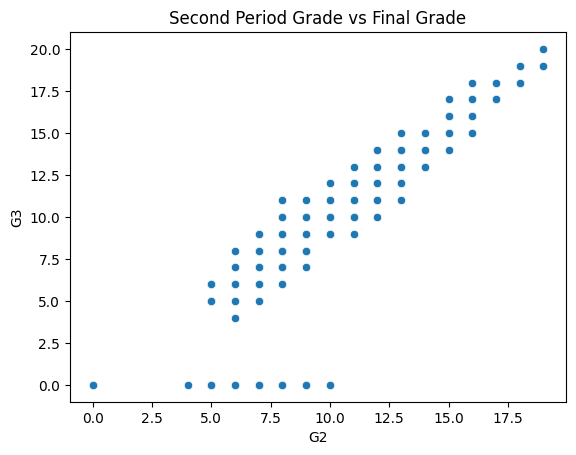

In [87]:
sns.scatterplot(data=df, x="G2", y="G3")

plt.title("Second Period Grade vs Final Grade")
plt.show()

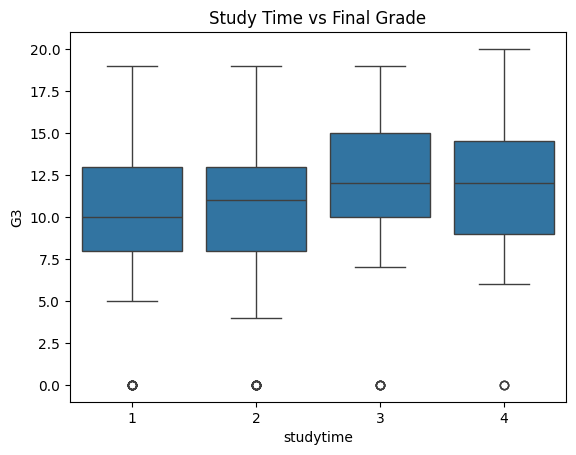

In [88]:
sns.boxplot(data=df, x="studytime", y="G3")

plt.title("Study Time vs Final Grade")
plt.show()

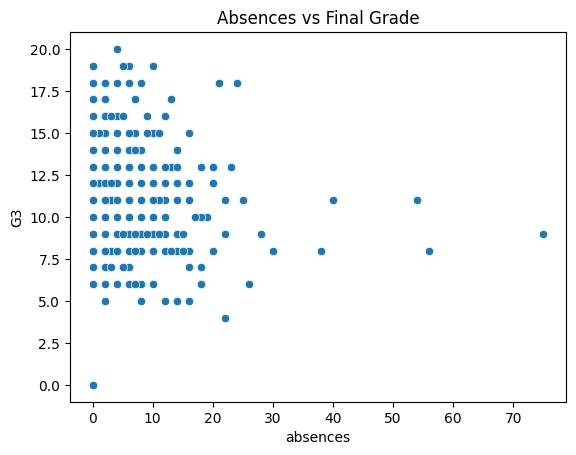

In [89]:
sns.scatterplot(data=df, x="absences", y="G3")

plt.title("Absences vs Final Grade")
plt.show()

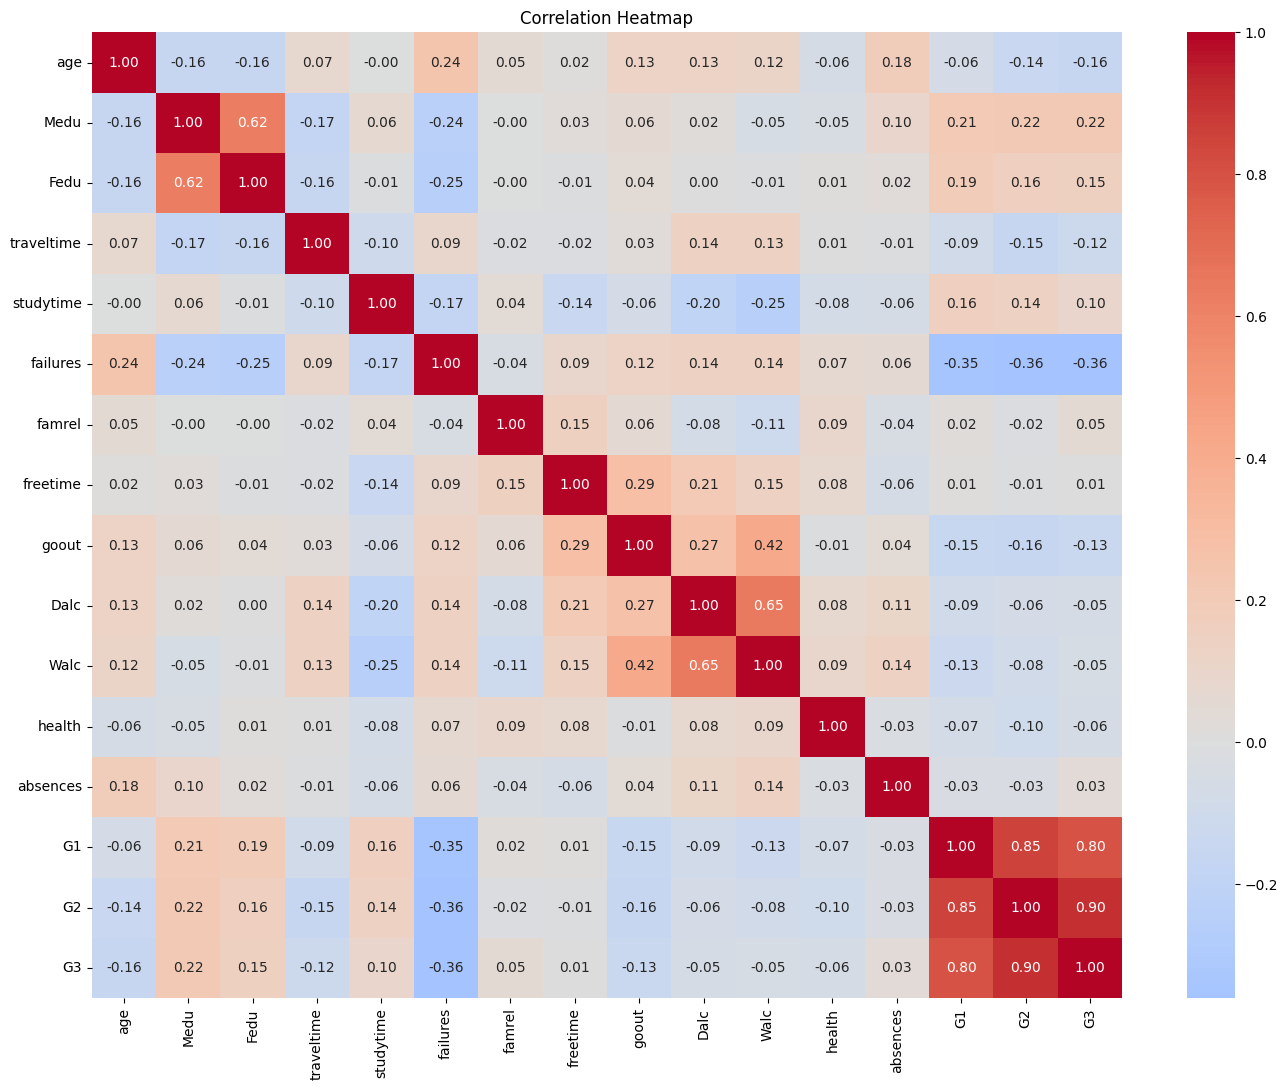

In [90]:
numeric_cols = df.select_dtypes(include=np.number).columns

corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(14, 11))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [91]:
corr_with_target = (
    corr_matrix["G3"]
    .drop("G3")
    .sort_values(ascending=False)
)

print(corr_with_target)

G2            0.904868
G1            0.801468
Medu          0.217147
Fedu          0.152457
studytime     0.097820
famrel        0.051363
absences      0.034247
freetime      0.011307
Walc         -0.051939
Dalc         -0.054660
health       -0.061335
traveltime   -0.117142
goout        -0.132791
age          -0.161579
failures     -0.360415
Name: G3, dtype: float64


In [92]:
# Count zero grades
print("G1 zeros:", (df["G1"] == 0).sum())
print("G2 zeros:", (df["G2"] == 0).sum())
print("G3 zeros:", (df["G3"] == 0).sum())

# Percentage of zero final grades
zero_percentage = (df["G3"] == 0).mean() * 100

print("G3 zero percentage:", zero_percentage)

# Inspect students with zero final grades
zero_students = df.loc[
    df["G3"] == 0,
    ["G1", "G2", "G3", "absences",
     "studytime", "failures"]
]

display(zero_students)

G1 zeros: 0
G2 zeros: 13
G3 zeros: 38
G3 zero percentage: 9.620253164556962


,G1,G2,G3,absences,studytime,failures
128,7,4,0,0,1,2
130,12,0,0,0,3,2
131,8,0,0,0,1,0
134,9,0,0,0,2,0
135,11,0,0,0,3,0
136,10,0,0,0,2,0
137,4,0,0,0,1,2
140,7,9,0,0,4,0
144,5,0,0,0,1,3
146,6,7,0,0,2,3


In [93]:
Q1 = df["absences"].quantile(0.25)
Q3 = df["absences"].quantile(0.75)

IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

absences_outliers = df[
    df["absences"] > upper_bound
]

print("Upper Bound:", upper_bound)
print("Number of Outliers:", len(absences_outliers))

display(
    absences_outliers[
        ["absences", "G1", "G2", "G3"]
    ].sort_values("absences", ascending=False)
)

Upper Bound: 20.0
Number of Outliers: 15


,absences,G1,G2,G3
276,75,10,9,9
183,56,9,9,8
74,54,11,12,11
315,40,13,11,11
307,38,8,9,8
280,30,8,8,8
205,28,10,9,9
103,26,7,6,6
40,25,7,10,11
198,24,18,18,18


In [94]:
categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_cols:

    print(f"\n========== {col} ==========")

    summary = (
        df.groupby(col)["G3"]
        .agg(["count", "mean", "median", "std"])
        .round(2)
        .sort_values("mean", ascending=False)
    )

    display(summary)


========== school ==========


,count,mean,median,std
school,,,,
GP,349,10.49,11.0,4.63
MS,46,9.85,10.0,4.24



========== sex ==========


,count,mean,median,std
sex,,,,
M,187,10.91,11.0,4.50
F,208,9.97,10.0,4.62



========== address ==========


,count,mean,median,std
address,,,,
U,307,10.67,11.0,4.56
R,88,9.51,10.0,4.56


... (24 outputs left out)


========== internet ==========


,count,mean,median,std
internet,,,,
yes,329,10.62,11.0,4.58
no,66,9.41,10.0,4.49



========== romantic ==========


,count,mean,median,std
romantic,,,,
no,263,10.84,11.0,4.39
yes,132,9.58,11.0,4.86


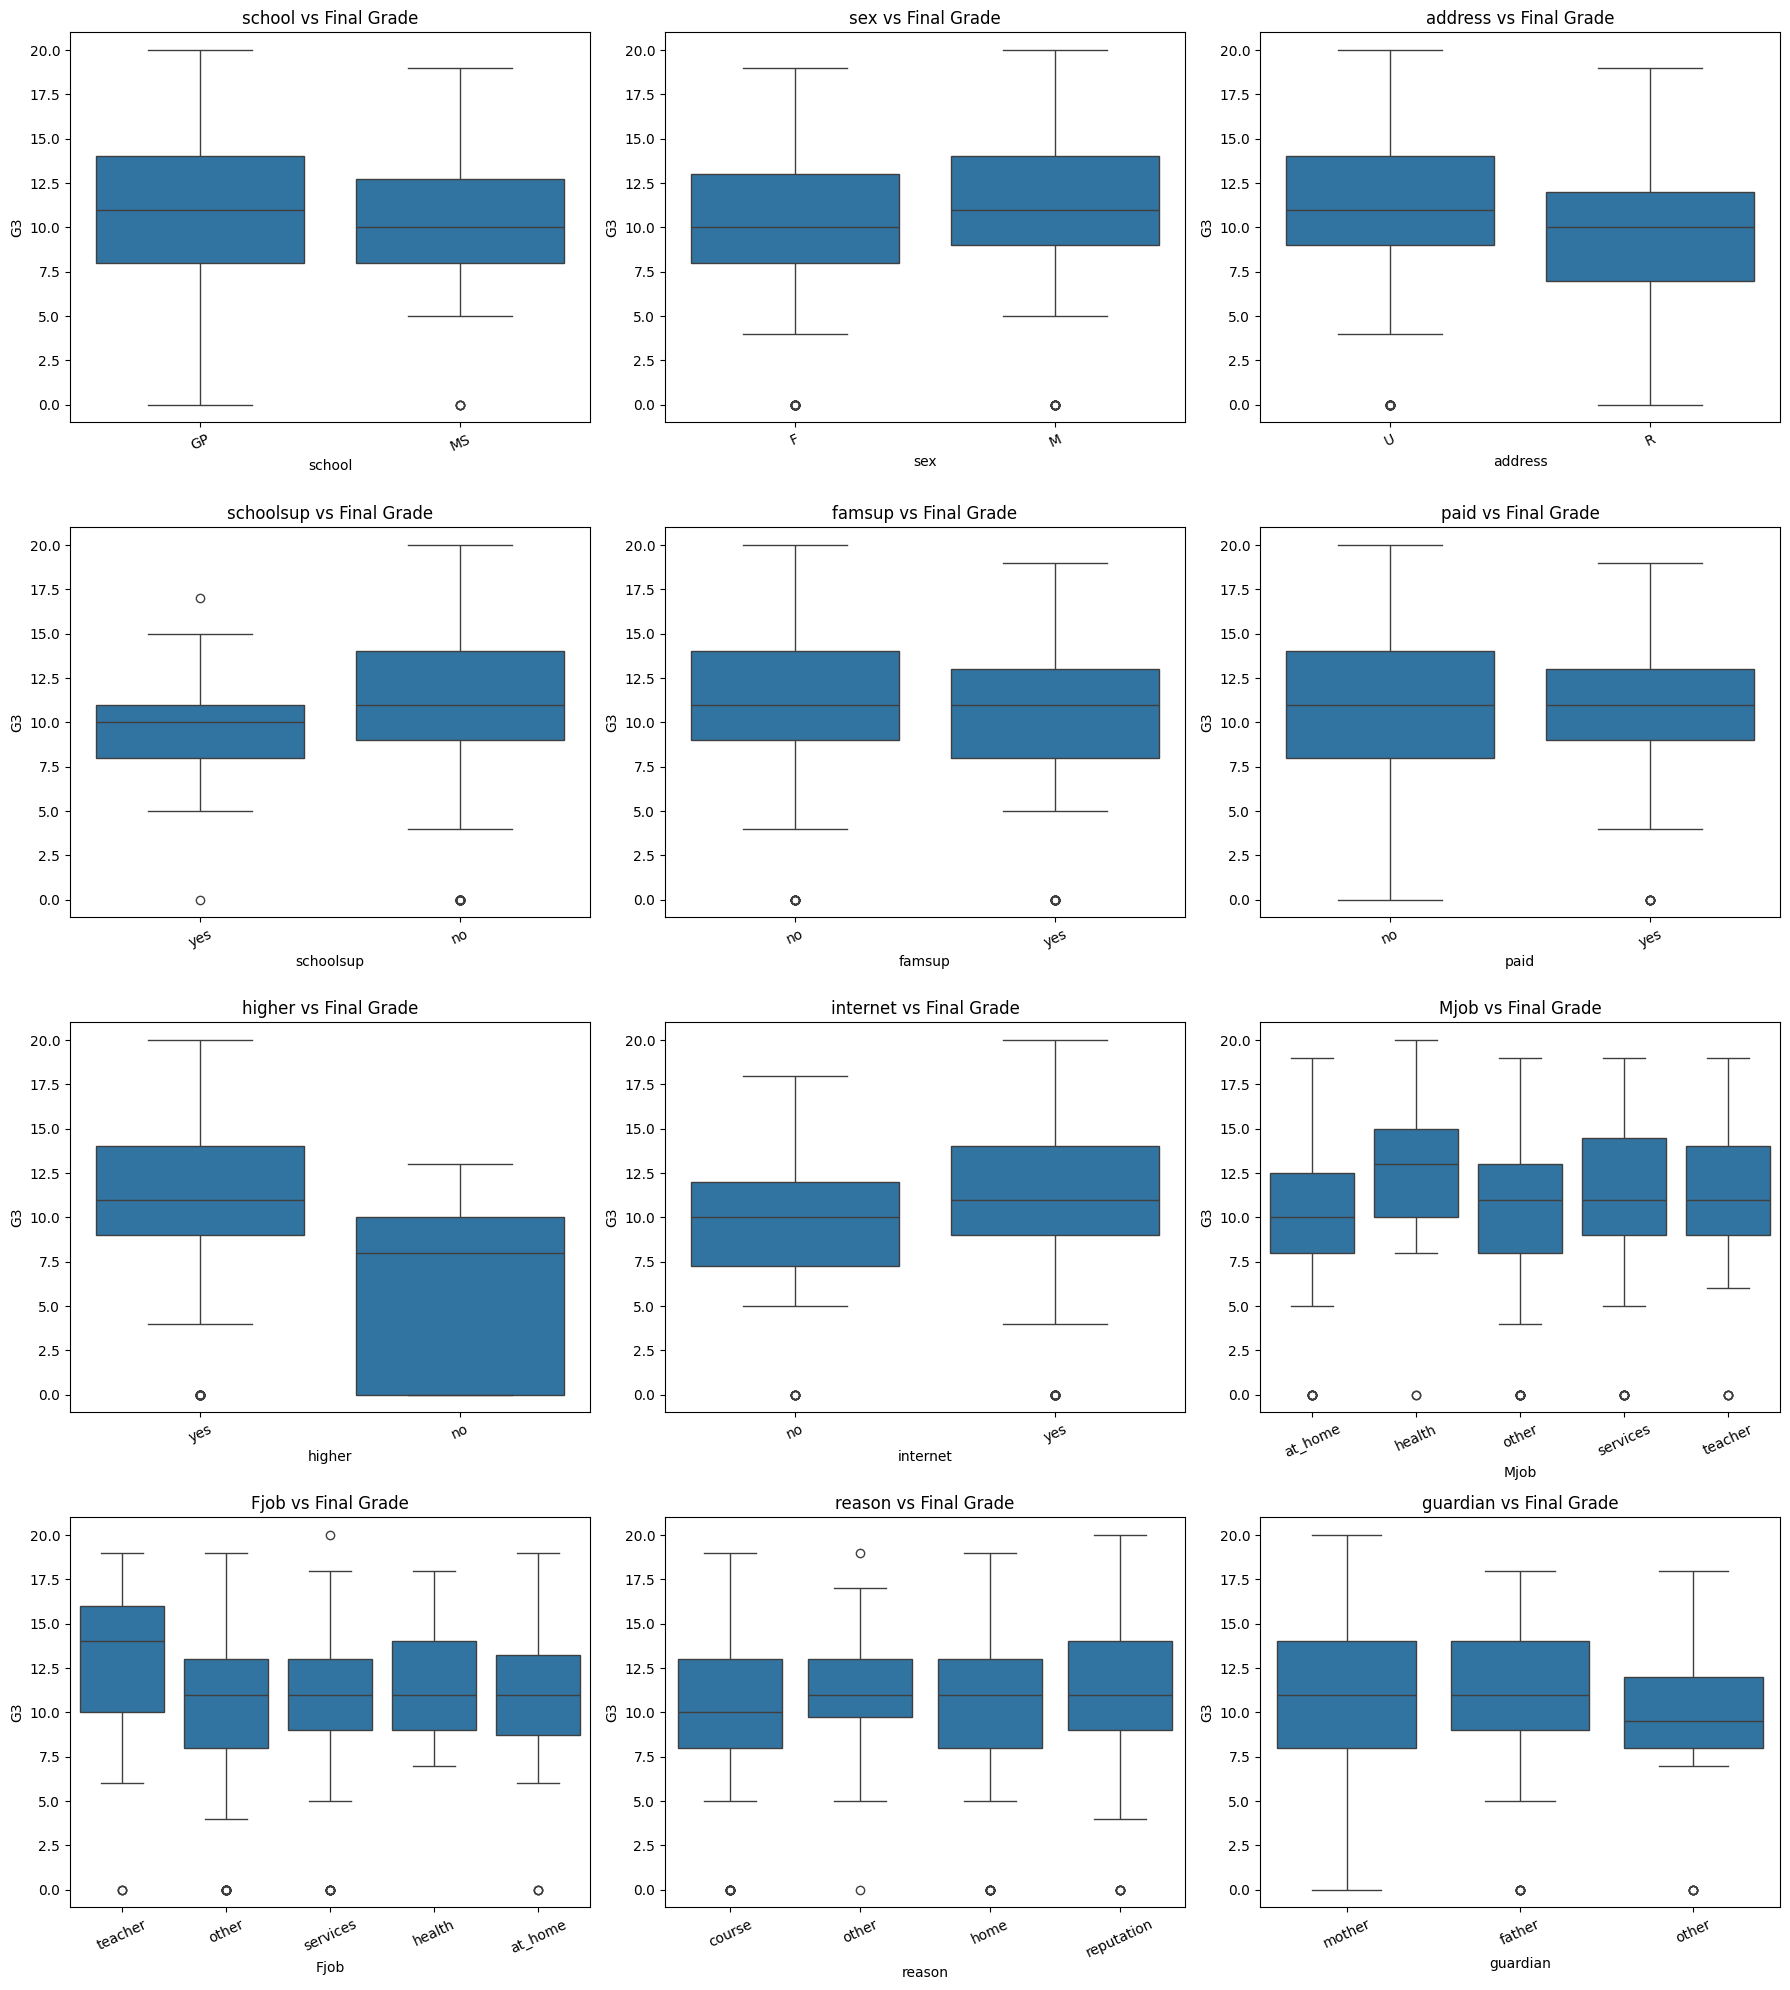

In [95]:
selected_cats = [
    "school",
    "sex",
    "address",
    "schoolsup",
    "famsup",
    "paid",
    "higher",
    "internet",
    "Mjob",
    "Fjob",
    "reason",
    "guardian"
]

fig, axes = plt.subplots(4, 3, figsize=(18, 20))

for col, ax in zip(selected_cats, axes.flatten()):

    sns.boxplot(
        data=df,
        x=col,
        y="G3",
        ax=ax
    )

    ax.set_title(f"{col} vs Final Grade")
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

In [96]:
from sklearn.model_selection import train_test_split

# Define features and target
X = df.drop(columns=["G3"])
y = df["G3"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (316, 32)
X_test: (79, 32)
y_train: (316,)
y_test: (79,)


In [97]:
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Features:", len(numeric_features))
print("Categorical Features:", len(categorical_features))

print("\nNumerical:", numeric_features)
print("\nCategorical:", categorical_features)

Numerical Features: 15
Categorical Features: 17

Numerical: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']

Categorical: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


In [98]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

def create_preprocessor(scale_numeric=True):

    numerical_transformer = (
        StandardScaler()
        if scale_numeric
        else "passthrough"
    )

    categorical_transformer = OneHotEncoder(
        handle_unknown="ignore"
    )

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "num",
                numerical_transformer,
                numeric_features
            ),
            (
                "cat",
                categorical_transformer,
                categorical_features
            )
        ]
    )

    return preprocessor

In [99]:
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor

models = {

    "Linear Regression": Pipeline([
        ("preprocessor", create_preprocessor(scale_numeric=True)),
        ("model", LinearRegression())
    ]),

    "Ridge Regression": Pipeline([
        ("preprocessor", create_preprocessor(scale_numeric=True)),
        ("model", Ridge(alpha=1.0))
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", create_preprocessor(scale_numeric=False)),
        ("model", DecisionTreeRegressor(random_state=42))
    ])

}

In [100]:
for name, model in models.items():

    model.fit(X_train, y_train)

    print(name, "Training Completed")

Linear Regression Training Completed
Ridge Regression Training Completed
Decision Tree Training Completed


In [101]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

results = []

predictions = {}

for name, model in models.items():

    # Predict on test data
    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    # Calculate evaluation metrics
    r2 = r2_score(y_test, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )

    mae = mean_absolute_error(y_test, y_pred)

    results.append({
        "Model": name,
        "R2": r2,
        "RMSE": rmse,
        "MAE": mae
    })


# Create comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
)

display(results_df.round(3))

,Model,R2,RMSE,MAE
1,Ridge Regression,0.726,2.372,1.639
0,Linear Regression,0.724,2.378,1.647
2,Decision Tree,0.678,2.571,1.316


In [102]:
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

comparison = []

for name, model in models.items():

    # Predictions on training data
    train_pred = model.predict(X_train)

    # Predictions on testing data
    test_pred = model.predict(X_test)

    comparison.append({
        "Model": name,

        "Train R2": r2_score(y_train, train_pred),
        "Test R2": r2_score(y_test, test_pred),

        "Train RMSE": np.sqrt(
            mean_squared_error(y_train, train_pred)
        ),

        "Test RMSE": np.sqrt(
            mean_squared_error(y_test, test_pred)
        ),

        "Train MAE": mean_absolute_error(
            y_train, train_pred
        ),

        "Test MAE": mean_absolute_error(
            y_test, test_pred
        )
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(3))

,Model,Train R2,Test R2,Train RMSE,Test RMSE,Train MAE,Test MAE
0,Linear Regression,0.866,0.724,1.68,2.378,1.164,1.647
1,Ridge Regression,0.866,0.726,1.68,2.372,1.162,1.639
2,Decision Tree,1.000,0.678,0.00,2.571,0.000,1.316


In [103]:
from sklearn.model_selection import KFold, cross_validate

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "r2": "r2",
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error"
}

cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    cv_results.append({
        "Model": name,

        "CV R2 Mean": scores["test_r2"].mean(),

        "CV R2 Std": scores["test_r2"].std(),

        "CV RMSE Mean": -scores["test_rmse"].mean(),

        "CV RMSE Std": scores["test_rmse"].std(),

        "CV MAE Mean": -scores["test_mae"].mean()
    })

cv_df = pd.DataFrame(cv_results)

display(cv_df.round(3))

,Model,CV R2 Mean,CV R2 Std,CV RMSE Mean,CV RMSE Std,CV MAE Mean
0,Linear Regression,0.804,0.032,1.987,0.361,1.393
1,Ridge Regression,0.806,0.032,1.977,0.358,1.381
2,Decision Tree,0.796,0.078,2.007,0.545,1.089


In [104]:
from sklearn.model_selection import GridSearchCV

ridge_params = {
    "model__alpha": [
        0.001,
        0.01,
        0.1,
        1,
        10,
        100
    ]
}

ridge_search = GridSearchCV(
    estimator=models["Ridge Regression"],
    param_grid=ridge_params,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

ridge_search.fit(X_train, y_train)

print("Best Ridge Parameters:")
print(ridge_search.best_params_)

print("Best CV RMSE:")
print(-ridge_search.best_score_)

Best Ridge Parameters:
{'model__alpha': 10}
Best CV RMSE:
1.9372158986608288


In [105]:
tree_params = {
    "model__max_depth": [2, 3, 4, 5, 6, 8, None],

    "model__min_samples_split": [
        2, 5, 10, 15
    ],

    "model__min_samples_leaf": [
        1, 2, 4, 6, 8
    ]
}

tree_search = GridSearchCV(
    estimator=models["Decision Tree"],
    param_grid=tree_params,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

tree_search.fit(X_train, y_train)

print("Best Tree Parameters:")
print(tree_search.best_params_)

print("Best CV RMSE:")
print(-tree_search.best_score_)

Best Tree Parameters:
{'model__max_depth': 5, 'model__min_samples_leaf': 4, 'model__min_samples_split': 2}
Best CV RMSE:
1.602648973552424


In [106]:
best_models = {
    "Linear Regression": models["Linear Regression"],
    "Tuned Ridge": ridge_search.best_estimator_,
    "Tuned Decision Tree": tree_search.best_estimator_
}

final_results = []

for name, model in best_models.items():

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    final_results.append({
        "Model": name,

        "Train R2": r2_score(y_train, train_pred),
        "Test R2": r2_score(y_test, test_pred),

        "Train RMSE": np.sqrt(
            mean_squared_error(y_train, train_pred)
        ),

        "Test RMSE": np.sqrt(
            mean_squared_error(y_test, test_pred)
        ),

        "Test MAE": mean_absolute_error(
            y_test, test_pred
        )
    })

final_comparison = pd.DataFrame(final_results)

display(
    final_comparison.sort_values(
        by="Test RMSE"
    ).round(3)
)

,Model,Train R2,Test R2,Train RMSE,Test RMSE,Test MAE
1,Tuned Ridge,0.864,0.736,1.690,2.328,1.589
2,Tuned Decision Tree,0.941,0.731,1.112,2.347,1.380
0,Linear Regression,0.866,0.724,1.680,2.378,1.647


In [107]:
# Select the best model
final_model = ridge_search.best_estimator_

# Predict final grades for test students
predicted_grades = final_model.predict(X_test)

# Store predictions with student row indices
predictions = pd.Series(
    predicted_grades,
    index=X_test.index,
    name="Predicted_G3"
)

# Set support threshold
support_threshold = 10

# Identify students who may need additional support
support_mask = predictions <= support_threshold

# Select students flagged for review
support_candidates = X_test.loc[
    support_mask,
    ["age", "studytime", "absences", "G1", "G2"]
].copy()

# Keep dataset row index for reference
support_candidates.insert(
    0,
    "Dataset_Row",
    support_candidates.index
)

# Add predicted grades
support_candidates["Predicted_G3"] = (
    predictions.loc[support_candidates.index].round(2)
)

# Sort by predicted grade
support_candidates = support_candidates.sort_values(
    by="Predicted_G3"
)

print("Total students in test set:", len(X_test))

print("Students needing review:",
      len(support_candidates))

display(support_candidates)

Total students in test set: 79
Students needing review: 38


,Dataset_Row,age,studytime,absences,G1,G2,Predicted_G3
137,137,16,1,0,4,0,-2.14
248,248,18,2,8,3,5,2.73
370,370,19,2,4,7,7,3.26
386,386,18,1,7,6,5,3.32
177,177,17,2,4,6,5,4.19
18,18,17,1,16,6,5,4.31
384,384,18,1,14,6,5,4.37
72,72,15,2,2,8,6,5.52
90,90,16,3,0,7,7,5.52
209,209,17,3,6,7,7,5.55


In [108]:
support_audit = pd.DataFrame({
    "Dataset_Row": X_test.index,
    "Predicted_G3": predictions.values,
    "Actual_G3": y_test.values
})

support_audit["Needs_Review"] = (
    support_audit["Predicted_G3"] <= support_threshold
)

support_audit["Prediction_Error"] = np.abs(
    support_audit["Actual_G3"] -
    support_audit["Predicted_G3"]
)

display(
    support_audit[
        support_audit["Needs_Review"]
    ].sort_values("Predicted_G3")
)

,Dataset_Row,Predicted_G3,Actual_G3,Needs_Review,Prediction_Error
36,137,-2.136179,0,True,2.136179
2,248,2.725386,5,True,2.274614
64,370,3.259444,9,True,5.740556
54,386,3.322881,6,True,2.677119
63,177,4.186856,6,True,1.813144
78,18,4.310886,5,True,0.689114
35,384,4.373923,5,True,0.626077
34,90,5.516199,8,True,2.483801
40,72,5.516729,5,True,0.516729
11,209,5.547075,7,True,1.452925


In [109]:
support_audit["Predicted_G3_Raw"] = (
    support_audit["Predicted_G3"]
)

support_audit["Predicted_G3"] = (
    support_audit["Predicted_G3_Raw"]
    .clip(0, 20)
)

In [110]:
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Create evaluation DataFrame
support_evaluation = pd.DataFrame(
    index=X_test.index
)

support_evaluation["Actual_G3"] = y_test

support_evaluation["Predicted_G3"] = predictions

# Actual and predicted review status
support_evaluation["Actual_Review"] = (
    support_evaluation["Actual_G3"] <= 10
)

support_evaluation["Predicted_Review"] = (
    support_evaluation["Predicted_G3"] <= 10
)

# Calculate confusion matrix
y_true = support_evaluation["Actual_Review"]
y_pred = support_evaluation["Predicted_Review"]

tn, fp, fn, tp = confusion_matrix(
    y_true,
    y_pred,
    labels=[False, True]
).ravel()

print("True Positives:", tp)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Negatives:", tn)

print("\nPrecision:", precision_score(y_true, y_pred))
print("Recall:", recall_score(y_true, y_pred))
print("F1 Score:", f1_score(y_true, y_pred))

True Positives: 36
False Positives: 2
False Negatives: 2
True Negatives: 39

Precision: 0.9473684210526315
Recall: 0.9473684210526315
F1 Score: 0.9473684210526315
